# 유저 이탈 예측 모델링

### 모델링 목적: 업데이트·핫픽스 이후 이탈 위험 조기 탐지
30일 이내 이탈할 유저를 예측하여, **업데이트 및 핫픽스 영향 평가 및 최적화에 활용**

- **배경**: 성장 개편 업데이트(8/30) 이후 핫픽스 전까지 DAU가 평시보다 낮았고(평시 대비 -3.4%), 기존 유저도 감소함(7/31 이후 평시 대비 -7.2%).  
  9/8에 핫픽스를 적용했지만 다음 날 복귀 지원 프로모션이 시작되어, 핫픽스의 영향을 바로 평가하기 어려웠음.  
  핫픽스 효과는 프로모션 종료 후(9/16~9/28)에야 기존 유저 수로 확인할 수 있었음.

- **활용 방안**: 유저의 행동 데이터(접속일수, 플레이타임 변화, 마지막 접속 후 경과일 등)를 기반으로 이탈을 예측하는 모델을 업데이트·핫픽스 이후에 주기적으로 돌림.  
  이탈이 장기화되기 전, 이탈 위험 유저의 비율로 영향을 신속하게 추정할 수 있음.

- **기대 효과**: 업데이트나 핫픽스 이후 이탈 위험 유저가 늘어날 것으로 예상되면, 프로모션 등 다른 요인이 겹치기 전에 추가 업데이트, 핫픽스 등의 조치를 더 신속하게 결정할 수 있음.

- **한계**: 현재 모델은 기준일 전 14일의 행동 데이터를 사용해, 업데이트 직후 바로 적용하려면 변수 기간을 줄이는 등의 조정이 필요함.

### 데이터 개요
- **데이터 배경**: 가상 MMORPG **Astrasia Online** 서비스 데이터
- **분석 대상 테이블**
  - `users.csv`: 유저 정보
  - `daily_activity.csv`: 일별 접속, 플레이타임, 골드, 아이템
  - `funnel_events.csv`: 성장 퍼널 이벤트
  - `payments.csv`: 결제 내역
- **분석 대상 유저 수**: 5520명

### 모델 설명
기준일 기준 앞으로 30일 이내 접속할지 하지 않을지를 통해 유저 이탈 예측
30일 이상 접속하지 않을 경우 이탈로 정의

### 데이터 기간 설계

데이터에는 기간 내내 프로모션이 있어(여름 축제 1부 7/21~7/27, 2부 8/15~8/21, 복귀 지원 프로모션 9/9~9/15) 그 영향을 완전히 분리하지 못함  
대신 영향이 큰 구간이 학습 데이터에 섞이지 않도록 기간을 다음과 같이 설정함

- **변수 기간(14일, 7/27 ~ 8/9):** 여름 축제 1부(7/21~7/27)가 끝난 직후부터 시작. 7/27 하루는 여름 축제에 해당
- **정답 기간(30일, 8/10 ~ 9/8):** 복귀 지원 프로모션(9/9~9/15)이 시작되기 전날에 끝나도록 설정.  
  - 복귀 보상은 이탈한 유저를 다시 접속하게 만들어 이탈 라벨을 왜곡할 수 있어서 정답 기간에서 제외함

| 구분 | 기간 |
|---|---|
| 변수 기간(14일) | 7/27 ~ 8/9 |
| 기준일 t | 8/9 |
| 정답 기간(30일) | 8/10 ~ 9/8 |

**한계점:** 정답 기간에도 여름 축제 2부(8/15~8/21), 8/30 성장 개편 업데이트, 9/8 핫픽스가 포함되어 있어 그 영향은 분리하지 못함

### 평가 기준
`PR-AUC`  
소수의 관심 대상인 '진짜 이탈자(1)'를 얼마나 정확하고 꼼꼼하게 찾는지를 판단

## 1. 환경 설정

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.compose import make_column_selector as selector
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold


In [2]:
# 환경 설정
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# csv 파일 불러오기
users = pd.read_csv("../data/users.csv", parse_dates=["signup_date"])
daily = pd.read_csv("../data/daily_activity.csv", parse_dates=["date"])
events = pd.read_csv("../data/funnel_events.csv", parse_dates=["event_time"])
payments = pd.read_csv("../data/payments.csv", parse_dates=["paid_at"])

# 시드값 고정
SEED = 42

In [3]:
for name, df in [("users", users), ("daily", daily), ("events", events), ("payments", payments)]:
    print(f"[{name}]  {df.shape[0]:,}행 x {df.shape[1]}열")
    display(df.head())
    print()

[users]  34,000행 x 5열


,user_id,signup_date,country,platform,device_id
0,1,2025-07-01,JP,Mobile,DVE9166407B5
1,2,2025-07-01,KR,PC,DV1FAFC2BAAC
2,3,2025-07-01,KR,PC,DVDC9D892BDA
3,4,2025-07-01,KR,PC,DVF621F6D69A
4,5,2025-07-01,JP,Mobile,DV45428C7277



[daily]  268,799행 x 7열


,user_id,date,sessions,playtime_min,level,gold_earned,items_acquired
0,4,2026-07-01,4,428.1,55,90928,222
1,4,2026-07-02,3,433.3,56,131601,241
2,4,2026-07-03,5,345.8,56,119083,179
3,4,2026-07-04,2,492.9,56,90363,180
4,4,2026-07-05,7,300.0,56,98828,124



[events]  23,597행 x 3열


,user_id,event,event_time
0,4,reach_lv60,2026-07-18 12:08:58
1,5,guild_join,2026-09-09 23:21:58
2,6,reach_lv45,2026-07-10 13:23:44
3,8,reach_lv45,2026-07-23 21:31:09
4,11,reach_lv30,2026-07-05 00:12:04



[payments]  2,917행 x 3열


,user_id,paid_at,amount_krw
0,85,2026-08-17 22:27:46,5500
1,396,2026-09-03 23:55:39,33000
2,428,2026-09-02 21:49:16,33000
3,502,2026-09-01 23:55:01,55000
4,502,2026-09-26 15:49:13,11000


In [4]:
# 분석 대상 유저 추출

t = pd.Timestamp("2026-08-09")                     # 기준일
feat_start = t - pd.Timedelta(days=13)             # 7/27 (기준일 포함 14일)

# 7/27 ~ 8/9 접속 기록
d14 = daily[(daily["date"] >= feat_start) & (daily["date"] <= t)]

# 유저별 접속일수
active_days_by_user = d14.groupby("user_id")["date"].nunique()

# 3일 이상 접속한 유저만 users에서 뽑기
user_ids_3_days_and_more = active_days_by_user[active_days_by_user >= 3].index

print(f"분석 대상 유저 수: {len(user_ids_3_days_and_more)}명")

분석 대상 유저 수: 5520명


## 2. 피처 설계

In [5]:
# 테이블별, 분석 대상 기간 유저 데이터만 필터링
users_target = users[users["user_id"].isin(user_ids_3_days_and_more)]

daily_target = daily[daily["user_id"].isin(user_ids_3_days_and_more)
                     & (daily["date"] >= feat_start)
                     & (daily["date"] <= t)]

events_target = events[events["user_id"].isin(user_ids_3_days_and_more)
                       & (events["event_time"] >= feat_start)
                       & (events["event_time"] < t + pd.Timedelta(days=1))]

payments_target = payments[payments["user_id"].isin(user_ids_3_days_and_more)
                           & (payments["paid_at"] >= feat_start)
                           & (payments["paid_at"] < t + pd.Timedelta(days=1))]

print("users:", users_target.shape)
print("daily:", daily_target.shape)
print("events:", events_target.shape)
print("payments:", payments_target.shape)

users: (5520, 5)
daily: (35003, 7)
events: (2341, 3)
payments: (383, 3)


In [6]:
# users 테이블 피처 설계
feat_users = users_target[["user_id", "signup_date", "country", "platform"]].copy()

feat_users["days_since_signup"] = (t - feat_users["signup_date"]).dt.days + 1          # 파생 피처: 가입 후 지난 일수
feat_users["is_new"] = (feat_users["signup_date"] >= feat_start).astype(int)         # 파생 피처: 14일 이내 가입 여부

feat_users = feat_users.drop(columns=["signup_date"])
feat_users = feat_users.set_index("user_id")

print(f"users: {feat_users.shape}")
feat_users.head()

users: (5520, 4)


,country,platform,days_since_signup,is_new
user_id,,,,
4,KR,PC,405,0
6,KR,Mobile,405,0
7,KR,Mobile,405,0
8,KR,PC,405,0
47,JP,PC,405,0


In [7]:
# daily 테이블 피처 설계
feat_daily = daily_target.groupby("user_id").agg(
    active_days=("date", "nunique"),             # 지난 14일간 접속일수
    total_sessions=("sessions", "sum"),          # 총 세션 수
    total_playtime_min=("playtime_min", "sum"),  # 총 플레이타임(분)
    total_gold=("gold_earned", "sum"),           # 총 골드 획득량
    total_items=("items_acquired", "sum"),       # 총 아이템 획득량
    max_level=("level", "max"),                  # 지난 14일 중 최대 레벨
    last_active_date=("date", "max"),            # 마지막 접속일 (계산용)
)

# 마지막 접속 후 지난 일자
feat_daily["days_since_last_active_day"] = (t - feat_daily["last_active_date"]).dt.days
feat_daily = feat_daily.drop(columns=["last_active_date"])     # 마지막 접속일 날짜 컬럼 삭제

# 접속일 평균 추가
feat_daily["avg_sessions_per_active_day"] = feat_daily["total_sessions"] / feat_daily["active_days"]            # 접속일 평균 세션 수
feat_daily["avg_playtime_min_per_active_day"] = feat_daily["total_playtime_min"] / feat_daily["active_days"]    # 접속일 평균 플레이타임(분)
feat_daily["avg_gold_per_active_day"] = feat_daily["total_gold"] / feat_daily["active_days"]                    # 접속일 평균 골드 획득량
feat_daily["avg_items_per_active_day"] = feat_daily["total_items"] / feat_daily["active_days"]                  # 접속일 평균 아이템 획득량

# 최근 7일 / 이전 7일 플레이타임
recent_start = t - pd.Timedelta(days=6)     # 8/3 (최근 7일: 8/3 ~ 8/9, 이전 7일: 7/27 ~ 8/2)

feat_daily["playtime_min_recent_7d"] = (daily_target[daily_target["date"] >= recent_start]
                                        .groupby("user_id")["playtime_min"]
                                        .sum())
feat_daily["playtime_min_prev_7d"] = (daily_target[daily_target["date"] < recent_start]
                                      .groupby("user_id")["playtime_min"]
                                      .sum())

feat_daily[["playtime_min_recent_7d", "playtime_min_prev_7d"]] = (feat_daily[["playtime_min_recent_7d", "playtime_min_prev_7d"]]
                                                                  .fillna(0))

feat_daily["playtime_min_diff_7d"] = feat_daily["playtime_min_recent_7d"] - feat_daily["playtime_min_prev_7d"]   # 최근 - 이전 (음수면 줄어든 것)

print(f"daily: {feat_daily.shape}")
feat_daily.head()

daily: (5520, 14)


,active_days,total_sessions,total_playtime_min,total_gold,total_items,max_level,days_since_last_active_day,avg_sessions_per_active_day,avg_playtime_min_per_active_day,avg_gold_per_active_day,avg_items_per_active_day,playtime_min_recent_7d,playtime_min_prev_7d,playtime_min_diff_7d
user_id,,,,,,,,,,,,,,
4,13,38,5107.0,1285314,2561,60,0,2.923077,392.846154,98870.307692,197.000000,2741.5,2365.5,376.0
6,8,30,1198.6,233381,161,52,0,3.750000,149.825000,29172.625000,20.125000,543.4,655.2,-111.8
7,3,9,470.3,126282,80,40,4,3.000000,156.766667,42094.000000,26.666667,143.9,326.4,-182.5
8,6,13,1029.5,136066,149,51,3,2.166667,171.583333,22677.666667,24.833333,569.8,459.7,110.1
47,5,14,723.2,162933,158,56,0,2.800000,144.640000,32586.600000,31.600000,428.6,294.6,134.0


In [8]:
# events 테이블 피처 설계
feat_events = events_target[["user_id", "event"]]

# event 달성 여부(0/1)
feat_events = pd.crosstab(feat_events["user_id"], feat_events["event"])
feat_events = pd.DataFrame(index=user_ids_3_days_and_more).join(feat_events).fillna(0).astype(int)

print(f"events: {feat_events.shape}")
feat_events.head()

events: (5520, 7)


,first_dungeon,guild_join,reach_lv10,reach_lv30,reach_lv45,reach_lv60,tutorial_complete
user_id,,,,,,,
4,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0
47,0,0,0,0,0,0,0


In [9]:
# payments 테이블 피처 설계
feat_payments = payments_target.groupby("user_id").agg(
            total_amount_krw =("amount_krw", "sum"),        # 총 결제 금액(원)
            total_paid_count =("amount_krw", "count")       # 결제 횟수
)

feat_payments["has_paid"] = 1                               # 결제 여부

feat_payments = pd.DataFrame(index=user_ids_3_days_and_more).join(feat_payments)    # 결제하지 않은 유저는 has_paid 에서 0으로 표기
feat_payments = feat_payments.fillna(0).astype(int)

print(f"payment: {feat_payments.shape}")
feat_payments.head()

payment: (5520, 3)


,total_amount_krw,total_paid_count,has_paid
user_id,,,
4,0,0,0
6,0,0,0
7,0,0,0
8,0,0,0
47,0,0,0


## 3. Train/Test 데이터 준비

In [10]:
# 피처 합치기
X = feat_users.join([feat_daily, feat_events, feat_payments])

# 라벨: 8/10 ~ 9/8 접속이 없으면 이탈
label_start = t + pd.Timedelta(days=1)      # 8/10 (정답 기간 시작)
label_end = t + pd.Timedelta(days=30)       # 9/8  (정답 기간 끝)

daily_label = daily[(daily["date"] >= label_start) & (daily["date"] <= label_end)]
not_churned_user_ids = daily_label["user_id"].unique()

is_active = X.index.isin(not_churned_user_ids)
y = np.where(is_active, 0, 1)               # 0: 잔류, 1: 이탈

print(f"X: {X.shape}")
print(f"y: {y.shape}")

X: (5520, 28)
y: (5520,)


In [11]:
pd.set_option("display.max_columns", None)
display(X.head())
X.columns

,country,platform,days_since_signup,is_new,active_days,total_sessions,total_playtime_min,total_gold,total_items,max_level,days_since_last_active_day,avg_sessions_per_active_day,avg_playtime_min_per_active_day,avg_gold_per_active_day,avg_items_per_active_day,playtime_min_recent_7d,playtime_min_prev_7d,playtime_min_diff_7d,first_dungeon,guild_join,reach_lv10,reach_lv30,reach_lv45,reach_lv60,tutorial_complete,total_amount_krw,total_paid_count,has_paid
user_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,
4,KR,PC,405,0,13,38,5107.0,1285314,2561,60,0,2.923077,392.846154,98870.307692,197.000000,2741.5,2365.5,376.0,0,0,0,0,0,0,0,0,0,0
6,KR,Mobile,405,0,8,30,1198.6,233381,161,52,0,3.750000,149.825000,29172.625000,20.125000,543.4,655.2,-111.8,0,0,0,0,0,0,0,0,0,0
7,KR,Mobile,405,0,3,9,470.3,126282,80,40,4,3.000000,156.766667,42094.000000,26.666667,143.9,326.4,-182.5,0,0,0,0,0,0,0,0,0,0
8,KR,PC,405,0,6,13,1029.5,136066,149,51,3,2.166667,171.583333,22677.666667,24.833333,569.8,459.7,110.1,0,0,0,0,0,0,0,0,0,0
47,JP,PC,405,0,5,14,723.2,162933,158,56,0,2.800000,144.640000,32586.600000,31.600000,428.6,294.6,134.0,0,0,0,0,0,0,0,0,0,0


Index(['country', 'platform', 'days_since_signup', 'is_new', 'active_days',
       'total_sessions', 'total_playtime_min', 'total_gold', 'total_items',
       'max_level', 'days_since_last_active_day',
       'avg_sessions_per_active_day', 'avg_playtime_min_per_active_day',
       'avg_gold_per_active_day', 'avg_items_per_active_day',
       'playtime_min_recent_7d', 'playtime_min_prev_7d',
       'playtime_min_diff_7d', 'first_dungeon', 'guild_join', 'reach_lv10',
       'reach_lv30', 'reach_lv45', 'reach_lv60', 'tutorial_complete',
       'total_amount_krw', 'total_paid_count', 'has_paid'],
      dtype='str')

In [12]:
# train/test 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.3,
                                                    stratify=y,
                                                    random_state=SEED)

cat_cols = X_train.select_dtypes(exclude="number").columns
num_cols = X_train.select_dtypes(include="number").columns

print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

X_train: (3864, 28)
y_train: (3864,)
X_test: (1656, 28)
y_test: (1656,)


In [13]:
# 함수 지정: 전처리 -> 학습 -> 평가 -> results 저장 -> 점수 출력

onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)    # 원-핫 인코더

results = {}   # 모델별 평가 점수 저장

def run_model(model_name, clf, X_train, X_test, scale=False):

    # 1. 전처리기 (scale=True: 로지스틱 회귀용, False: 트리용)
    cat_cols = X_train.select_dtypes(exclude="number").columns
    num_cols = X_train.select_dtypes(include="number").columns
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler() if scale else "passthrough", num_cols),
    ])

    # 2. 학습 및 예측
    model = Pipeline([("prep", prep), ("clf", clf)])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    # 3. 평가 (precision/recall/f1은 이탈(1) 클래스 기준)
    results[model_name] = {
        "n_features": X_train.shape[1],
        "PR-AUC": average_precision_score(y_test, y_proba),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
    }
    
    return model

# 함수 지정: 지금까지 돌린 모델 전체 결과표 만들기
def get_results_table():
    results_table = pd.DataFrame(results).T.round(3)
    results_table["n_features"] = results_table["n_features"].astype(int)   # 28.0 -> 28
    return results_table

## 4. 모델링

### 4-1. 로지스틱 회귀 모델(베이스라인 모델)

In [14]:
lr_model = run_model("Logistic Regression (Baseline)",
                     LogisticRegression(max_iter=1000, class_weight="balanced"),
                     X_train,
                     X_test,
                     scale=True)

get_results_table()

,n_features,PR-AUC,ROC-AUC,precision,recall,f1
Logistic Regression (Baseline),28,0.545,0.935,0.195,0.831,0.316


### 4-2. 랜덤 포레스트, LightGBM, XGBoost, Catboost

In [15]:
# 이탈(1) 1명당 잔류(0)가 몇 명인지 (XGBoost의 불균형 보정용)
positive_weight = (y_train == 0).sum() / (y_train == 1).sum()

# 돌릴 모델 목록 (모델 이름: 모델)
tree_models = {
    "Random Forest": RandomForestClassifier(n_estimators=300,
                                            class_weight="balanced",
                                            random_state=SEED),
    "LightGBM": LGBMClassifier(class_weight="balanced",
                               random_state=SEED,
                               verbose=-1),                        # 로그 보이지 않기
    "XGBoost": XGBClassifier(scale_pos_weight=positive_weight,
                             random_state=SEED),
    "CatBoost": CatBoostClassifier(auto_class_weights="Balanced",
                                   random_state=SEED,
                                   verbose=0,                      # 로그 보이지 않기
                                   allow_writing_files=False),     # 불필요한 디스크 파일 생성 방지
}

for model_name, clf in tree_models.items():
    run_model(model_name, clf, X_train, X_test)

get_results_table()

,n_features,PR-AUC,ROC-AUC,precision,recall,f1
Logistic Regression (Baseline),28,0.545,0.935,0.195,0.831,0.316
Random Forest,28,0.542,0.916,0.561,0.627,0.592
LightGBM,28,0.557,0.928,0.540,0.576,0.557
XGBoost,28,0.564,0.911,0.533,0.542,0.538
CatBoost,28,0.573,0.931,0.539,0.695,0.607


In [16]:
X_train

,country,platform,days_since_signup,is_new,active_days,total_sessions,total_playtime_min,total_gold,total_items,max_level,days_since_last_active_day,avg_sessions_per_active_day,avg_playtime_min_per_active_day,avg_gold_per_active_day,avg_items_per_active_day,playtime_min_recent_7d,playtime_min_prev_7d,playtime_min_diff_7d,first_dungeon,guild_join,reach_lv10,reach_lv30,reach_lv45,reach_lv60,tutorial_complete,total_amount_krw,total_paid_count,has_paid
user_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,
20931,US,Mobile,137,0,6,19,684.7,121359,132,49,3,3.166667,114.116667,20226.500000,22.000000,196.0,488.7,-292.7,0,0,0,0,0,0,0,0,0,0
11601,OTHER,PC,264,0,3,10,507.4,129359,78,52,0,3.333333,169.133333,43119.666667,26.000000,224.8,282.6,-57.8,0,0,0,0,0,0,0,0,0,0
15979,US,Mobile,204,0,8,27,1121.3,196480,209,60,0,3.375000,140.162500,24560.000000,26.125000,285.9,835.4,-549.5,0,0,0,0,0,1,0,0,0,0
27718,US,Mobile,44,0,10,25,1602.9,315691,257,60,0,2.500000,160.290000,31569.100000,25.700000,633.8,969.1,-335.3,0,0,0,0,0,0,0,0,0,0
23761,US,PC,98,0,3,12,553.8,65121,52,43,0,4.000000,184.600000,21707.000000,17.333333,370.5,183.3,187.2,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29006,OTHER,PC,21,0,4,16,680.8,103683,127,28,1,4.000000,170.200000,25920.750000,31.750000,330.2,350.6,-20.4,1,0,0,0,0,0,0,0,0,0
11943,TW,Mobile,260,0,3,5,131.8,23891,25,28,0,1.666667,43.933333,7963.666667,8.333333,131.8,0.0,131.8,0,0,0,0,0,0,0,0,0,0
6863,KR,PC,325,0,10,27,1544.8,361688,248,60,0,2.700000,154.480000,36168.800000,24.800000,845.3,699.5,145.8,0,0,0,0,0,1,0,0,0,0


### 4-3. 피처 엔지니어링

In [17]:
feat_daily_2 = feat_daily.copy()

# 지난 14일간 오른 레벨 수
level_by_user = daily_target.groupby("user_id")["level"]
feat_daily_2["level_gained"] = level_by_user.max() - level_by_user.min()

# 기준일 포함 최근 3일 내 접속 여부 (0/1)
feat_daily_2["is_active_last_3d"] = (feat_daily_2["days_since_last_active_day"] <= 2).astype(int)

In [18]:
# 새 피처를 포함해 X 다시 만들기 (y는 위에서 만든 것을 그대로 사용)
X_2 = feat_users.join([feat_daily_2, feat_events, feat_payments])

# train/test 분리: y는 이미 분리되어 있으므로 X만 분리
X_train_2, X_test_2 = train_test_split(X_2,
                                       test_size=0.3,
                                       stratify=y,
                                       random_state=SEED)

print(f"X_2: {X_2.shape}")
print(f"X_train_2: {X_train_2.shape}")
print(f"X_test_2: {X_test_2.shape}")

X_2: (5520, 30)
X_train_2: (3864, 30)
X_test_2: (1656, 30)


In [19]:
run_model("Logistic Regression (Feature Engineered)",
          LogisticRegression(max_iter=1000, class_weight="balanced"),
          X_train_2,
          X_test_2,
          scale=True)

for model_name, clf in tree_models.items():
    run_model(model_name + " (Feature Engineered)", clf, X_train_2, X_test_2)

get_results_table()

,n_features,PR-AUC,ROC-AUC,precision,recall,f1
Logistic Regression (Baseline),28,0.545,0.935,0.195,0.831,0.316
Random Forest,28,0.542,0.916,0.561,0.627,0.592
LightGBM,28,0.557,0.928,0.540,0.576,0.557
XGBoost,28,0.564,0.911,0.533,0.542,0.538
CatBoost,28,0.573,0.931,0.539,0.695,0.607
Logistic Regression (Feature Engineered),30,0.576,0.936,0.199,0.831,0.321
Random Forest (Feature Engineered),30,0.573,0.928,0.562,0.610,0.585
LightGBM (Feature Engineered),30,0.559,0.926,0.540,0.576,0.557
XGBoost (Feature Engineered),30,0.581,0.911,0.583,0.593,0.588
CatBoost (Feature Engineered),30,0.572,0.921,0.500,0.644,0.563


### 4-4. 피처 중요도 확인

In [20]:
# 함수 지정: Feature Importance 계산 -> 그래프 출력 -> 값 반환
def plot_feature_importance(model, X_data, y_data, title):
    importance_result = permutation_importance(model, X_data, y_data,
                                               scoring="average_precision",
                                               n_repeats=10,
                                               random_state=SEED)

    importance = pd.Series(importance_result.importances_mean,
                           index=X_data.columns).sort_values()

    importance.plot(kind="barh", figsize=(6, 9), title=title)
    plt.show()
    return importance

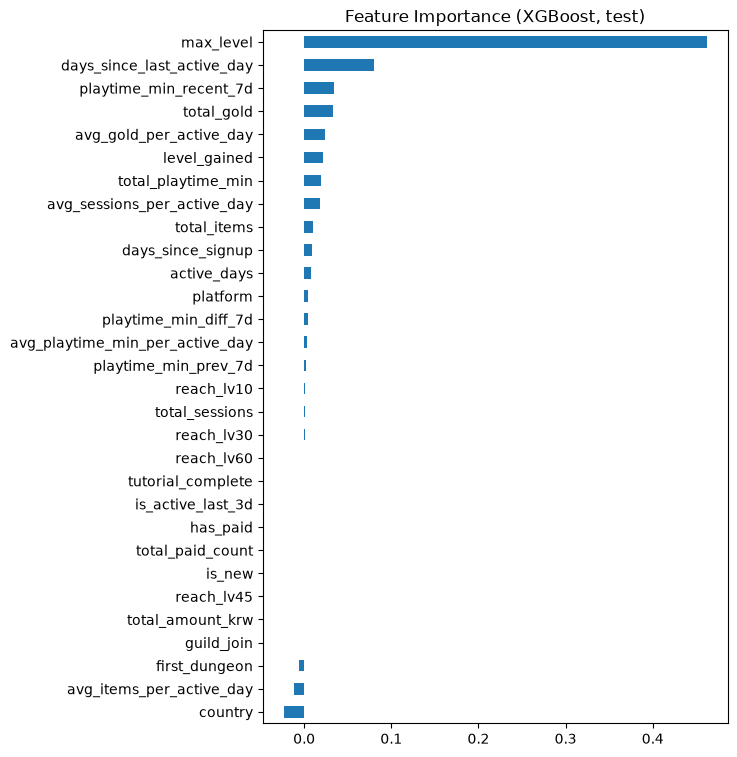

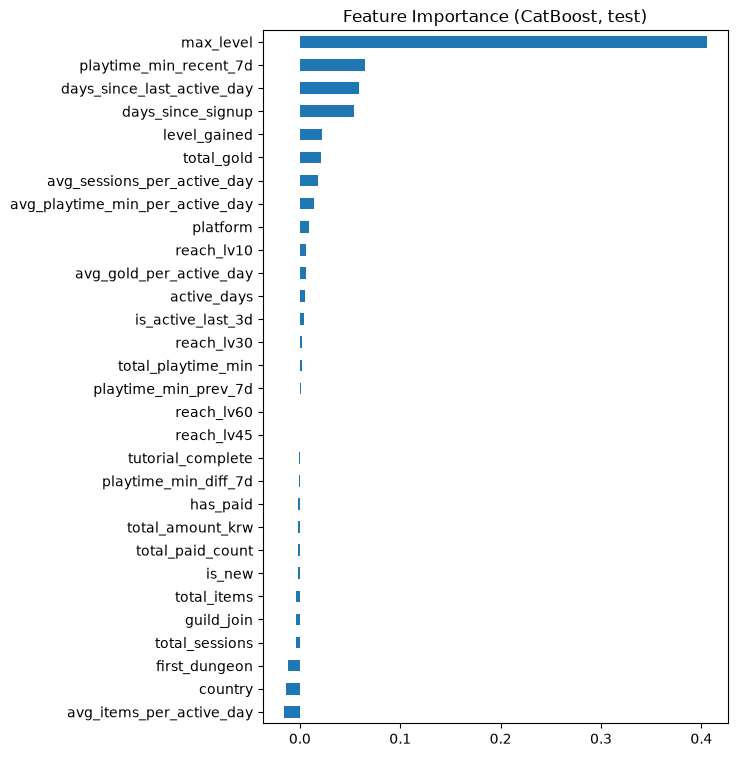

In [21]:
# XGBoost Feature Importance
xgb_model = run_model("XGBoost (Feature Engineered)",
                      XGBClassifier(scale_pos_weight=positive_weight,
                                    random_state=SEED),
                      X_train_2,
                      X_test_2)

# CatBoost Feature Importance
catboost_model = run_model("CatBoost (Feature Engineered)",
                           CatBoostClassifier(auto_class_weights="Balanced",
                                              random_state=SEED,
                                              verbose=0,
                                              allow_writing_files=False),
                           X_train_2,
                           X_test_2)

xgb_importance = plot_feature_importance(xgb_model, X_test_2, y_test,
                                         "Feature Importance (XGBoost, test)")

catboost_importance = plot_feature_importance(catboost_model, X_test_2, y_test,
                                              "Feature Importance (CatBoost, test)")

In [22]:
# train 점수와 test 점수 비교 (차이가 클수록 과적합)
models_to_check = {
    "XGBoost": xgb_model,
    "CatBoost": catboost_model,
}

for model_name, model in models_to_check.items():
    train_proba = model.predict_proba(X_train_2)[:, 1]
    test_proba = model.predict_proba(X_test_2)[:, 1]

    train_score = average_precision_score(y_train, train_proba)
    test_score = average_precision_score(y_test, test_proba)

    print(f"{model_name}: train {train_score:.3f} / test {test_score:.3f} / 차이 {train_score - test_score:.3f}")

XGBoost: train 1.000 / test 0.581 / 차이 0.419
CatBoost: train 0.998 / test 0.572 / 차이 0.427


### 4-5. 최적 파라미터 서치 및 튜닝

In [23]:
# 과적합이 의심되어 Grid Search를 통하여 최적 파라미터 서치

# XGBoost - 시험해 볼 설정값 조합 (3 x 3 x 3 = 27가지)
xgb_param_grid = {
    "clf__max_depth": [2, 3, 4],            # 나무 깊이
    "clf__n_estimators": [100, 200, 300],   # 나무 개수
    "clf__learning_rate": [0.03, 0.05, 0.1],   # 한 번에 배우는 정도
}

xgb_grid = GridSearchCV(xgb_model,                      # 전처리기 + XGBoost가 묶인 파이프라인
                        xgb_param_grid,
                        scoring="average_precision",    # 평가 기준: PR-AUC
                        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
                        n_jobs=-1)                      # 컴퓨터의 모든 코어 사용

xgb_grid.fit(X_train_2, y_train)

# CatBoost - 시험해 볼 설정값 조합 (3 x 2 x 2 = 12가지)
catboost_param_grid = {
    "clf__depth": [2, 3, 4],                # 나무 깊이
    "clf__iterations": [200, 400],          # 나무 개수
    "clf__learning_rate": [0.03, 0.1],      # 한 번에 배우는 정도
}

catboost_grid = GridSearchCV(catboost_model,                  # 전처리기 + CatBoost가 묶인 파이프라인
                             catboost_param_grid,
                             scoring="average_precision",     # 평가 기준: PR-AUC
                             cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
                             n_jobs=-1)

catboost_grid.fit(X_train_2, y_train)

print("[XGBoost]")
print("최적 설정:", xgb_grid.best_params_)
print(f"최적 CV PR-AUC: {xgb_grid.best_score_:.3f}")
print("")
print("[CatBoost]")
print("최적 설정:", catboost_grid.best_params_)
print(f"최적 CV PR-AUC: {catboost_grid.best_score_:.3f}")

[XGBoost]
최적 설정: {'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__n_estimators': 100}
최적 CV PR-AUC: 0.496

[CatBoost]
최적 설정: {'clf__depth': 4, 'clf__iterations': 200, 'clf__learning_rate': 0.03}
최적 CV PR-AUC: 0.484


In [24]:
# 최적 설정의 이름에서 앞의 "clf__" 떼어내기 (예: "clf__max_depth" -> "max_depth")
xgb_best_params = {name.replace("clf__", ""): value
                   for name, value in xgb_grid.best_params_.items()}

catboost_best_params = {name.replace("clf__", ""): value
                        for name, value in catboost_grid.best_params_.items()}

# 최적 설정으로 다시 학습
xgb_model_tuned = run_model("XGBoost (Tuned)",
                            XGBClassifier(**xgb_best_params,
                                          scale_pos_weight=positive_weight,
                                          random_state=SEED),
                            X_train_2,
                            X_test_2)

catboost_model_tuned = run_model("CatBoost (Tuned)",
                                 CatBoostClassifier(**catboost_best_params,
                                                    auto_class_weights="Balanced",
                                                    random_state=SEED,
                                                    verbose=0,
                                                    allow_writing_files=False),
                                 X_train_2,
                                 X_test_2)

get_results_table()

,n_features,PR-AUC,ROC-AUC,precision,recall,f1
Logistic Regression (Baseline),28,0.545,0.935,0.195,0.831,0.316
Random Forest,28,0.542,0.916,0.561,0.627,0.592
LightGBM,28,0.557,0.928,0.540,0.576,0.557
XGBoost,28,0.564,0.911,0.533,0.542,0.538
CatBoost,28,0.573,0.931,0.539,0.695,0.607
Logistic Regression (Feature Engineered),30,0.576,0.936,0.199,0.831,0.321
Random Forest (Feature Engineered),30,0.573,0.928,0.562,0.610,0.585
LightGBM (Feature Engineered),30,0.559,0.926,0.540,0.576,0.557
XGBoost (Feature Engineered),30,0.581,0.911,0.583,0.593,0.588
CatBoost (Feature Engineered),30,0.572,0.921,0.500,0.644,0.563


### 4-6. 튜닝 후 피처 중요도 확인

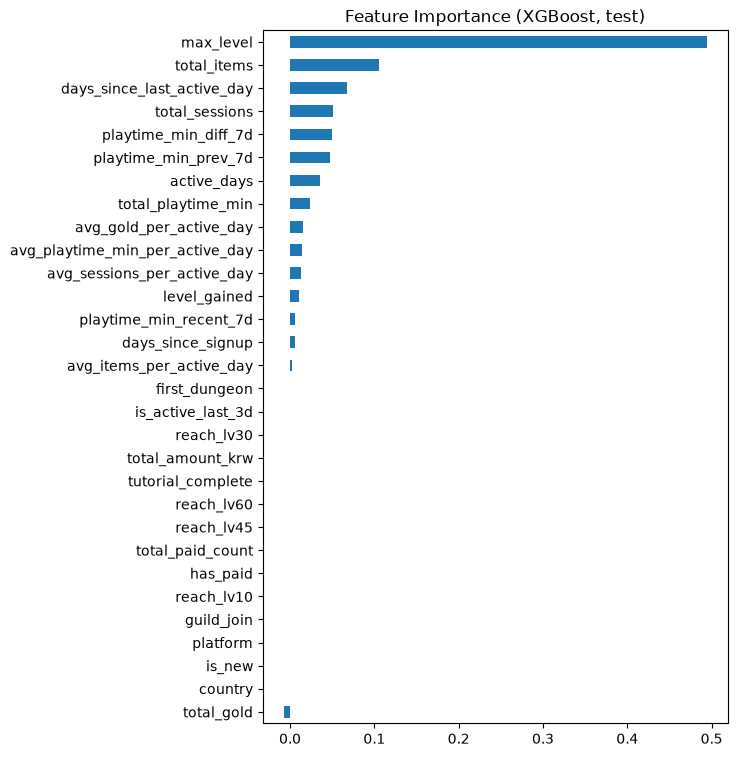

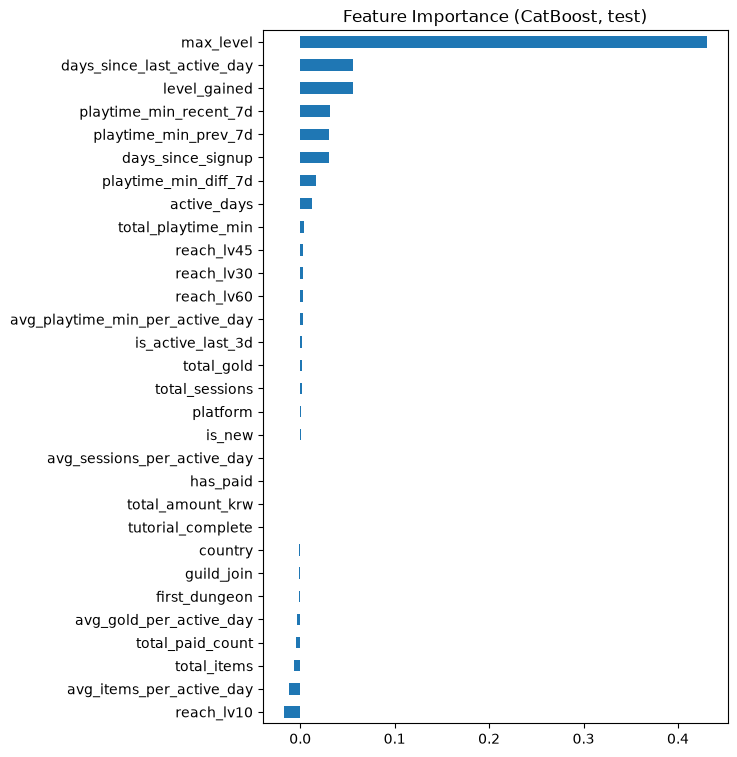

In [25]:
# 튜닝 후 Feature Importance (test 데이터 기준)
xgb_importance_tuned = plot_feature_importance(xgb_model_tuned,
                                               X_test_2,
                                               y_test,
                                               "Feature Importance (XGBoost, test)")

catboost_importance_tuned = plot_feature_importance(catboost_model_tuned,
                                                    X_test_2,
                                                    y_test,
                                                    "Feature Importance (CatBoost, test)")

In [26]:
# 튜닝 후 train 점수와 test 점수 비교 (차이가 클수록 과적합)
models_to_check = {
    "XGBoost": xgb_model_tuned,
    "CatBoost": catboost_model_tuned,
}

for model_name, model in models_to_check.items():
    train_proba = model.predict_proba(X_train_2)[:, 1]
    test_proba = model.predict_proba(X_test_2)[:, 1]

    train_score = average_precision_score(y_train, train_proba)
    test_score = average_precision_score(y_test, test_proba)

    print(f"{model_name}: train {train_score:.3f} / test {test_score:.3f} / 차이 {train_score - test_score:.3f}")

XGBoost: train 0.597 / test 0.611 / 차이 -0.014
CatBoost: train 0.653 / test 0.614 / 차이 0.039


## **결론**
- 튜닝한 XGBoost와 CatBoost의 성능은 거의 같았음 (test PR-AUC 0.611, 0.614)
- 두 모델 모두 train과 test의 PR-AUC 차이가 0.04 이내로, 튜닝 후 과적합이 해소된 것으로 보임
- 사전에 정한 평가 기준인 PR-AUC가 근소하게 높은 **CatBoost(Tuned)**를 최종 모델로 선택함